# Formative 3: Probability Distributions, Bayesian Probability and Gradient Descent

This notebook is what we present from. It runs every part of the assignment and shows the results, plots and handwritten pages.
The functions live in the part folders (`part1_em/`, `part2_bayes/`, `part4_gd_code/`), and the notebook imports them instead of copying them, so each piece of logic is written once.

| Part | Topic | Source |
|---|---|---|
| 1 | EM algorithm for a mixture of two Gaussians (fathers vs children) | `part1_em/em_gmm.py` |
| 2 | Bayes' theorem, P(Positive given keyword), on IMDb reviews | `part2_bayes/bayes_keywords.py` |
| 3 | Gradient descent by hand (matrix form) | `part3_manual/CamScanner 29-10-2026 09.16.pdf` |
| 4 | Gradient descent in code, with SciPy derivatives and Matplotlib plots | `part4_gd_code/gradient_descent.py` |

### Setup (needed for Google Colab)

Colab opens only this notebook, not the rest of the project, so the cell below fetches the project folder. It does nothing when you run the notebook from inside the project folder (Jupyter or VS Code).

In Colab, use **one** of these:
- **Option A: GitHub.** Paste the repository link into `REPO_URL`. If the repository is private, use Option B instead.
- **Option B: zip upload.** Leave `REPO_URL` empty, run the cell, and upload the project `.zip` when it asks.

In [1]:
import glob
import os
import subprocess
import sys
import zipfile

REPO_URL = ""   # e.g. "https://github.com/<your-team>/<repo-name>.git"


def find_project_root(start="."):
    hits = glob.glob(os.path.join(start, "**", "part1_em", "em_gmm.py"), recursive=True)
    return os.path.dirname(os.path.dirname(os.path.abspath(hits[0]))) if hits else None


root = find_project_root()
if root is None and REPO_URL:
    subprocess.run(["git", "clone", "-q", REPO_URL, "project"], check=True)
    root = find_project_root("project")
if root is None:
    zips = glob.glob("*.zip")
    if not zips and "google.colab" in sys.modules:
        from google.colab import files
        zips = list(files.upload().keys())
    for z in zips:
        zipfile.ZipFile(z).extractall("project")
    root = find_project_root("project")
if root is None:
    raise FileNotFoundError("Project folder not found: set REPO_URL or upload the project zip.")
os.chdir(root)
print("Project folder found:", os.path.basename(root))

# scipy.differentiate (used in Part 4) needs SciPy 1.15 or newer
import scipy
if tuple(int(p) for p in scipy.__version__.split(".")[:2]) < (1, 15):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scipy>=1.15"], check=True)
    print("SciPy upgraded. Restart the runtime (Runtime > Restart session) and run the notebook again.")

Project folder found: gradient_descentlr_bayesian_probabilityDistribution_formative_3_math_ml-main


In [2]:
from IPython.display import Image, Markdown, display

ROOT = os.path.abspath("")
for folder in ("part1_em", "part2_bayes", "part4_gd_code"):
    sys.path.insert(0, os.path.join(ROOT, folder))

import em_gmm
import bayes_keywords
import gradient_descent

OUT = os.path.join(ROOT, "outputs")
os.makedirs(OUT, exist_ok=True)

---
## Part 1: EM algorithm on Galton heights

We pool the **205 father heights** (one per family) with the **934 child heights** and throw the labels away. That leaves 1,139 unlabeled numbers, which we model as a mixture of two Gaussians:

$$p(x) = \pi_1\,\mathcal N(x\mid\mu_1,\sigma_1^2) + \pi_2\,\mathcal N(x\mid\mu_2,\sigma_2^2)$$

Component 1 = Children, component 2 = Parents (Fathers).

- **Initialization.** μ at the 25th and 75th percentiles, both σ² at the overall variance, π = 0.5 / 0.5.
- **E-step.** For every point, the responsibility is $r_i = \dfrac{\pi_1 \mathcal N(x_i\mid\mu_1,\sigma_1^2)}{\pi_1 \mathcal N(x_i\mid\mu_1,\sigma_1^2) + \pi_2 \mathcal N(x_i\mid\mu_2,\sigma_2^2)}$, the probability that point i belongs to the children. This is a soft assignment.
- **M-step.** Refit each Gaussian using those weights: $N_1=\sum r_i$, $\mu_1=\sum r_i x_i / N_1$, $\sigma_1^2=\sum r_i (x_i-\mu_1)^2 / N_1$, $\pi_1 = N_1/n$, and the same for component 2 with weights $1-r_i$.
- **Stopping rule.** Stop when the log-likelihood changes by less than $10^{-6}$ between iterations.

In [3]:
fathers, children = em_gmm.load_heights()
data = fathers + children            # labels thrown away from here on
print(f"Pooled {len(data)} unlabeled heights ({len(fathers)} fathers + {len(children)} children)\n")

final, history = em_gmm.run_em(data)

print("=== Tracking table: initial state + first two iterations ===")
em_gmm.print_table(history, rows=[0, 1, 2])
print(f"\n=== Converged after {len(history) - 1} iterations ===")
em_gmm.print_table(history, rows=[len(history) - 1])
em_gmm.save_markdown_table(history, os.path.join(OUT, "part1_em_tracking_table.md"))

Pooled 1139 unlabeled heights (205 fathers + 934 children)



=== Tracking table: initial state + first two iterations ===
Iteration            mu1 (Children)  mu2 (Parents)   sigma1^2   sigma2^2      pi1      pi2   Log-Likelihood
-----------------------------------------------------------------------------------------------------------
0 (Initialization)          64.5000        70.0000    12.7241    12.7241   0.5000   0.5000       -3119.8222
1                           65.2205        69.2054     9.0603     8.4468   0.5011   0.4989       -3057.9135
2                           65.1609        69.2600     8.9420     8.1040   0.5005   0.4995       -3056.9719

=== Converged after 319 iterations ===
Iteration            mu1 (Children)  mu2 (Parents)   sigma1^2   sigma2^2      pi1      pi2   Log-Likelihood
-----------------------------------------------------------------------------------------------------------
319                         64.1772        69.5186     5.3024     6.0410   0.4325   0.5675       -3046.9895


### Classification demo: the coach's test height

Change `TEST_HEIGHT` to the number the coach gives (set `UNITS = "cm"` if it is in centimetres) and re-run the cell. The code applies Bayes' rule with the fitted mixture and prints the exact posteriors.

In [4]:
TEST_HEIGHT = 70
UNITS = "in"

em_gmm.print_classification(TEST_HEIGHT, final, UNITS);


=== Classifying test height 70 in (70.00 in) ===
Likelihood  N(x|Children) = 0.007082   N(x|Fathers) = 0.159229
Prior x Likelihood         = 0.003063             = 0.090365
Evidence p(x)              = 0.093428
P(Child  | x) = 0.032784  (3.28%)
P(Parent | x) = 0.967216  (96.72%)
Prediction: PARENT (Father)


### Should we just draw a line at the global mean and average each pile?

**No.** Here is what that baseline gives on our data:

In [5]:
g, low, high = em_gmm.naive_mean_split(data)
print(f"Global mean = {g:.4f}")
print(f"Pile below: n={len(low)}  mean={em_gmm.mean(low):.4f}  var={em_gmm.variance(low):.4f}")
print(f"Pile above: n={len(high)}  mean={em_gmm.mean(high):.4f}  var={em_gmm.variance(high):.4f}")
print(f"Fathers wrongly put in the 'low' pile : {sum(f < g for f in fathers)}/{len(fathers)}")
print(f"Children wrongly put in the 'high' pile: {sum(c >= g for c in children)}/{len(children)}")
print("\nTrue labels (used only for this check, never for fitting):")
print(f"  children: mean={em_gmm.mean(children):.4f}  var={em_gmm.variance(children):.4f}")
print(f"  fathers : mean={em_gmm.mean(fathers):.4f}  var={em_gmm.variance(fathers):.4f}")

Global mean = 67.2085
Pile below: n=575  mean=64.2598  var=4.1428
Pile above: n=564  mean=70.2147  var=3.5711
Fathers wrongly put in the 'low' pile : 44/205
Children wrongly put in the 'high' pile: 403/934

True labels (used only for this check, never for fitting):
  children: mean=66.7459  var=12.7973
  fathers : mean=69.3161  var=6.9734


1. **The groups are not the same size** (934 children, 205 fathers), so the global mean is pulled towards the children and is not the boundary between the groups. 403 children land in the "tall" pile and 44 fathers in the "short" pile.
2. **Each pile's statistics come out biased.** Cutting overlapping bell curves and averaging each side pushes the means apart and shrinks the variances (4.14 and 3.57, against a true children's variance of 12.80).
3. **A hard split throws information away.** A person at 67.0 in and a person at 60 in both count 100% as "short". EM gives every point a soft responsibility, so points in the overlap count partly towards each group.
4. **A mean split gives no variances or mixing weights.** Without them there is no posterior P(Child given x) for a new height, only "left or right of the line".

**What EM actually found.** EM's "children" component (μ ≈ 64.2) is not the true children mean (66.7). The "children" in Galton's data are sons (about 69.2 in) and daughters (about 64.1 in), and sons are about as tall as fathers. So the strongest split in the pooled heights is by sex, not by generation: EM finds "mostly daughters" against "fathers + sons".

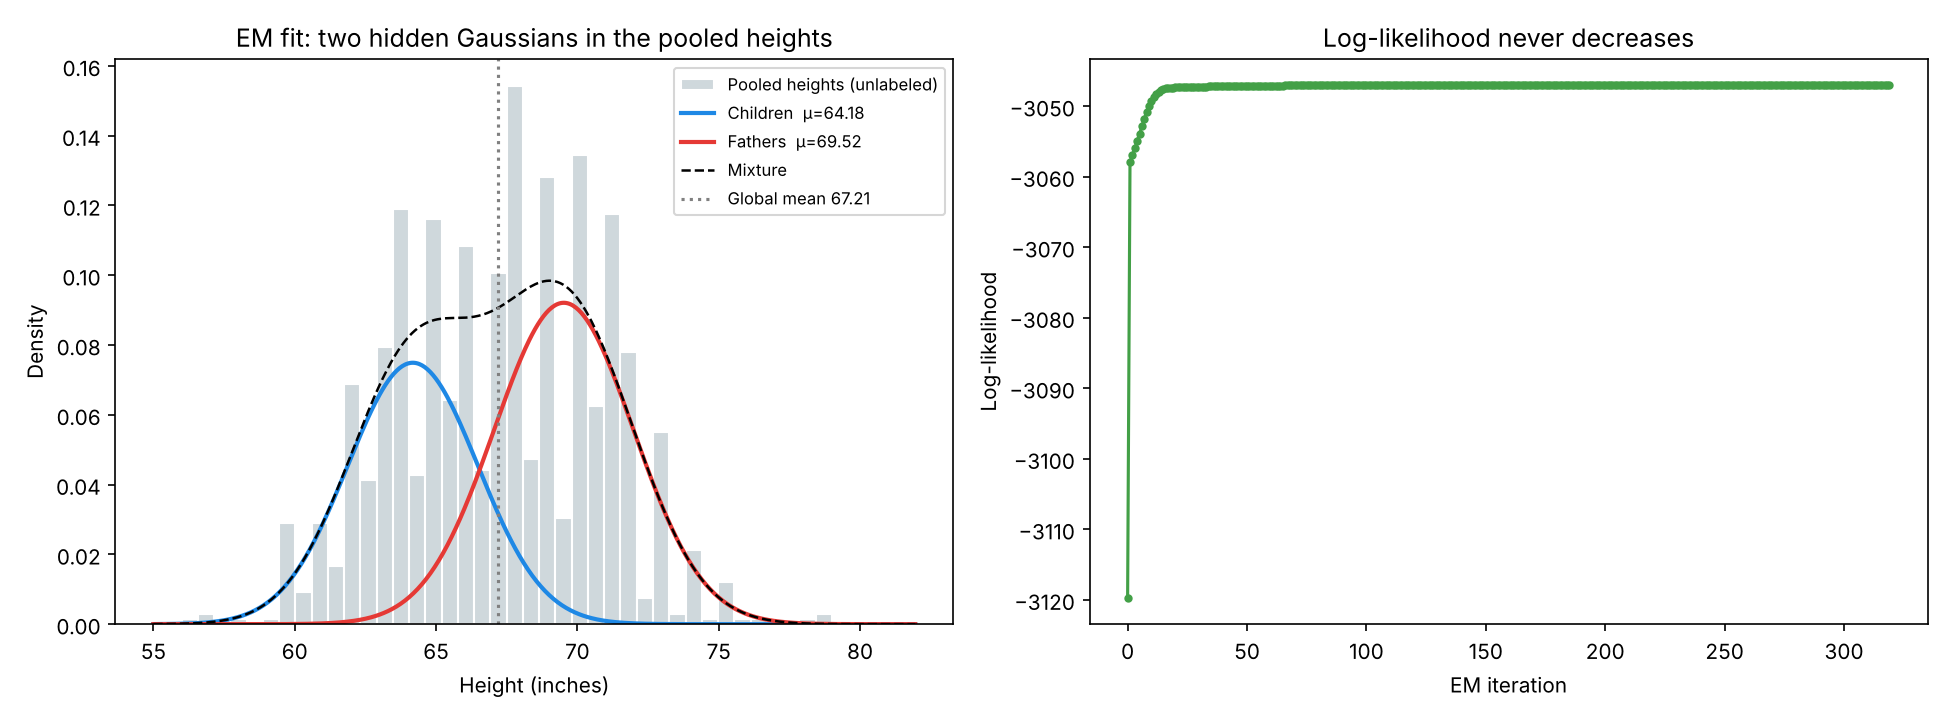

In [6]:
em_gmm.plot(data, history, fathers, children, os.path.join(OUT, "part1_em_fit.png"))
display(Image(os.path.join(OUT, "part1_em_fit.png")))

---
## Part 2: Bayes' theorem on IMDb reviews

We compute **P(Positive given keyword)** only (not P(Negative given keyword)):

$$P(\text{Pos}\mid kw) = \frac{P(kw\mid \text{Pos})\,P(\text{Pos})}{P(kw)}$$

A review "contains" a keyword if the word appears at least once as a whole word, after removing the `<br />` tags and lower-casing. The code uses only the Python standard library (`csv`, `re`).

**Keywords and why we chose them.**

| Group | Keywords | Why |
|---|---|---|
| Positive | *excellent, wonderful, masterpiece, superb* | Strong, unambiguous praise words. Each one is a verdict on the whole film, rarely used in a neutral or descriptive sense (unlike "good" or "great", which often appear in phrases like "not good" or "a great deal"). |
| Negative | *worst, waste, boring, awful* | Strong, unambiguous criticism. "worst" and "waste" (as in "waste of time") are verdicts on the whole film; "boring" and "awful" describe the viewing experience directly. |

We deliberately mixed very strong words (masterpiece, worst) with more everyday ones (boring) to test whether stronger words give stronger evidence. The results below show that this is not always true.

In [7]:
bayes_keywords.ensure_dataset()
keywords = bayes_keywords.POSITIVE_KEYWORDS + bayes_keywords.NEGATIVE_KEYWORDS
total, total_pos, kw_in_pos, kw_in_neg = bayes_keywords.count_everything(bayes_keywords.DATA, keywords)
print(f"Reviews: {total}  (positive {total_pos}, negative {total - total_pos})\n")

results = []
for group, kws in (("positive", bayes_keywords.POSITIVE_KEYWORDS), ("negative", bayes_keywords.NEGATIVE_KEYWORDS)):
    for k in kws:
        r = bayes_keywords.bayes_for_keyword(k, total, total_pos, kw_in_pos, kw_in_neg)
        r["group"] = group
        results.append(r)

print(f"{'keyword':<13}{'group':<10}{'P(Pos)':>8}{'P(kw|Pos)':>11}{'P(kw)':>9}{'P(Pos|kw)':>11}")
print("-" * 62)
for r in results:
    print(f"{r['keyword']:<13}{r['group']:<10}{r['prior']:>8.4f}{r['likelihood']:>11.4f}"
          f"{r['marginal']:>9.4f}{r['posterior']:>11.4f}")

Reviews: 50000  (positive 25000, negative 25000)

keyword      group       P(Pos)  P(kw|Pos)    P(kw)  P(Pos|kw)
--------------------------------------------------------------
excellent    positive    0.5000     0.1146   0.0710     0.8073
wonderful    positive    0.5000     0.0902   0.0555     0.8120
masterpiece  positive    0.5000     0.0350   0.0240     0.7300
superb       positive    0.5000     0.0410   0.0240     0.8557
worst        negative    0.5000     0.0164   0.0886     0.0924
waste        negative    0.5000     0.0070   0.0507     0.0687
boring       negative    0.5000     0.0236   0.0610     0.1938
awful        negative    0.5000     0.0112   0.0575     0.0977


### Per-keyword tables

Each block shows the four probabilities and the raw counts they come from.

In [8]:
display(Markdown("\n".join(bayes_keywords.keyword_block(r, total, total_pos) for r in results)))

### Keyword: `excellent`

| Quantity | Formula | Counts | Value |
|---|---|---|---|
| Prior P(Positive) | positive reviews / all reviews | 25000 / 50000 | 0.5000 |
| Likelihood P(excellent \| Positive) | positive reviews with word / positive reviews | 2865 / 25000 | 0.1146 |
| Marginal P(excellent) | reviews with word / all reviews | 3549 / 50000 | 0.0710 |
| **Posterior P(Positive \| excellent)** | likelihood × prior / marginal | 0.1146 × 0.5000 / 0.0710 | **0.8073** |

### Keyword: `wonderful`

| Quantity | Formula | Counts | Value |
|---|---|---|---|
| Prior P(Positive) | positive reviews / all reviews | 25000 / 50000 | 0.5000 |
| Likelihood P(wonderful \| Positive) | positive reviews with word / positive reviews | 2255 / 25000 | 0.0902 |
| Marginal P(wonderful) | reviews with word / all reviews | 2777 / 50000 | 0.0555 |
| **Posterior P(Positive \| wonderful)** | likelihood × prior / marginal | 0.0902 × 0.5000 / 0.0555 | **0.8120** |

### Keyword: `masterpiece`

| Quantity | Formula | Counts | Value |
|---|---|---|---|
| Prior P(Positive) | positive reviews / all reviews | 25000 / 50000 | 0.5000 |
| Likelihood P(masterpiece \| Positive) | positive reviews with word / positive reviews | 876 / 25000 | 0.0350 |
| Marginal P(masterpiece) | reviews with word / all reviews | 1200 / 50000 | 0.0240 |
| **Posterior P(Positive \| masterpiece)** | likelihood × prior / marginal | 0.0350 × 0.5000 / 0.0240 | **0.7300** |

### Keyword: `superb`

| Quantity | Formula | Counts | Value |
|---|---|---|---|
| Prior P(Positive) | positive reviews / all reviews | 25000 / 50000 | 0.5000 |
| Likelihood P(superb \| Positive) | positive reviews with word / positive reviews | 1026 / 25000 | 0.0410 |
| Marginal P(superb) | reviews with word / all reviews | 1199 / 50000 | 0.0240 |
| **Posterior P(Positive \| superb)** | likelihood × prior / marginal | 0.0410 × 0.5000 / 0.0240 | **0.8557** |

### Keyword: `worst`

| Quantity | Formula | Counts | Value |
|---|---|---|---|
| Prior P(Positive) | positive reviews / all reviews | 25000 / 50000 | 0.5000 |
| Likelihood P(worst \| Positive) | positive reviews with word / positive reviews | 409 / 25000 | 0.0164 |
| Marginal P(worst) | reviews with word / all reviews | 4428 / 50000 | 0.0886 |
| **Posterior P(Positive \| worst)** | likelihood × prior / marginal | 0.0164 × 0.5000 / 0.0886 | **0.0924** |

### Keyword: `waste`

| Quantity | Formula | Counts | Value |
|---|---|---|---|
| Prior P(Positive) | positive reviews / all reviews | 25000 / 50000 | 0.5000 |
| Likelihood P(waste \| Positive) | positive reviews with word / positive reviews | 174 / 25000 | 0.0070 |
| Marginal P(waste) | reviews with word / all reviews | 2533 / 50000 | 0.0507 |
| **Posterior P(Positive \| waste)** | likelihood × prior / marginal | 0.0070 × 0.5000 / 0.0507 | **0.0687** |

### Keyword: `boring`

| Quantity | Formula | Counts | Value |
|---|---|---|---|
| Prior P(Positive) | positive reviews / all reviews | 25000 / 50000 | 0.5000 |
| Likelihood P(boring \| Positive) | positive reviews with word / positive reviews | 591 / 25000 | 0.0236 |
| Marginal P(boring) | reviews with word / all reviews | 3049 / 50000 | 0.0610 |
| **Posterior P(Positive \| boring)** | likelihood × prior / marginal | 0.0236 × 0.5000 / 0.0610 | **0.1938** |

### Keyword: `awful`

| Quantity | Formula | Counts | Value |
|---|---|---|---|
| Prior P(Positive) | positive reviews / all reviews | 25000 / 50000 | 0.5000 |
| Likelihood P(awful \| Positive) | positive reviews with word / positive reviews | 281 / 25000 | 0.0112 |
| Marginal P(awful) | reviews with word / all reviews | 2875 / 50000 | 0.0575 |
| **Posterior P(Positive \| awful)** | likelihood × prior / marginal | 0.0112 × 0.5000 / 0.0575 | **0.0977** |


**What the numbers say.**
- The prior is exactly 0.5 (the dataset is balanced), so every move away from 0.5 comes from the keyword alone.
- Negative words are stronger evidence than positive ones: "waste" drops P(Positive) to about 7%, while the best positive word, "superb", lifts it only to about 86%.
- "masterpiece" is the weakest positive word (0.73) because of sarcasm and comparisons ("this is no masterpiece").
- "boring" is the weakest negative word (0.19) because positive reviews say "never boring" or "boring at first, but…". A keyword count cannot see negation.

---
## Part 3: Gradient descent by hand (matrix form)

Model: ŷ = X**m** + **b**, with one intercept b written as **b** = b·**1** = [b, b].

$$X=\begin{bmatrix}1&3\\4&10\end{bmatrix},\quad \mathbf y=\begin{bmatrix}5\\6\end{bmatrix},\quad \mathbf m^{(0)}=\begin{bmatrix}-1\\2\end{bmatrix},\quad \mathbf b^{(0)}=\begin{bmatrix}1\\1\end{bmatrix},\quad n=2,\quad \alpha=0.01$$

Chain rule with $u = X\mathbf m + \mathbf b - \mathbf y$ and $E = \frac{1}{n}u^\top u$:

$$\frac{\partial E}{\partial \mathbf m} = \frac{\partial u}{\partial \mathbf m}^{\!\top}\frac{\partial E}{\partial u} = \frac{2}{n}X^\top(\hat{\mathbf y}-\mathbf y), \qquad
\frac{\partial E}{\partial b} = \frac{\partial u}{\partial b}^{\!\top}\frac{\partial E}{\partial u} = \frac{2}{n}\mathbf 1^\top(\hat{\mathbf y}-\mathbf y)$$

The handwritten working, one update per member, is below. Update 1 gives **m** = [−1.45, 0.87] and **b** = [0.88, 0.88].

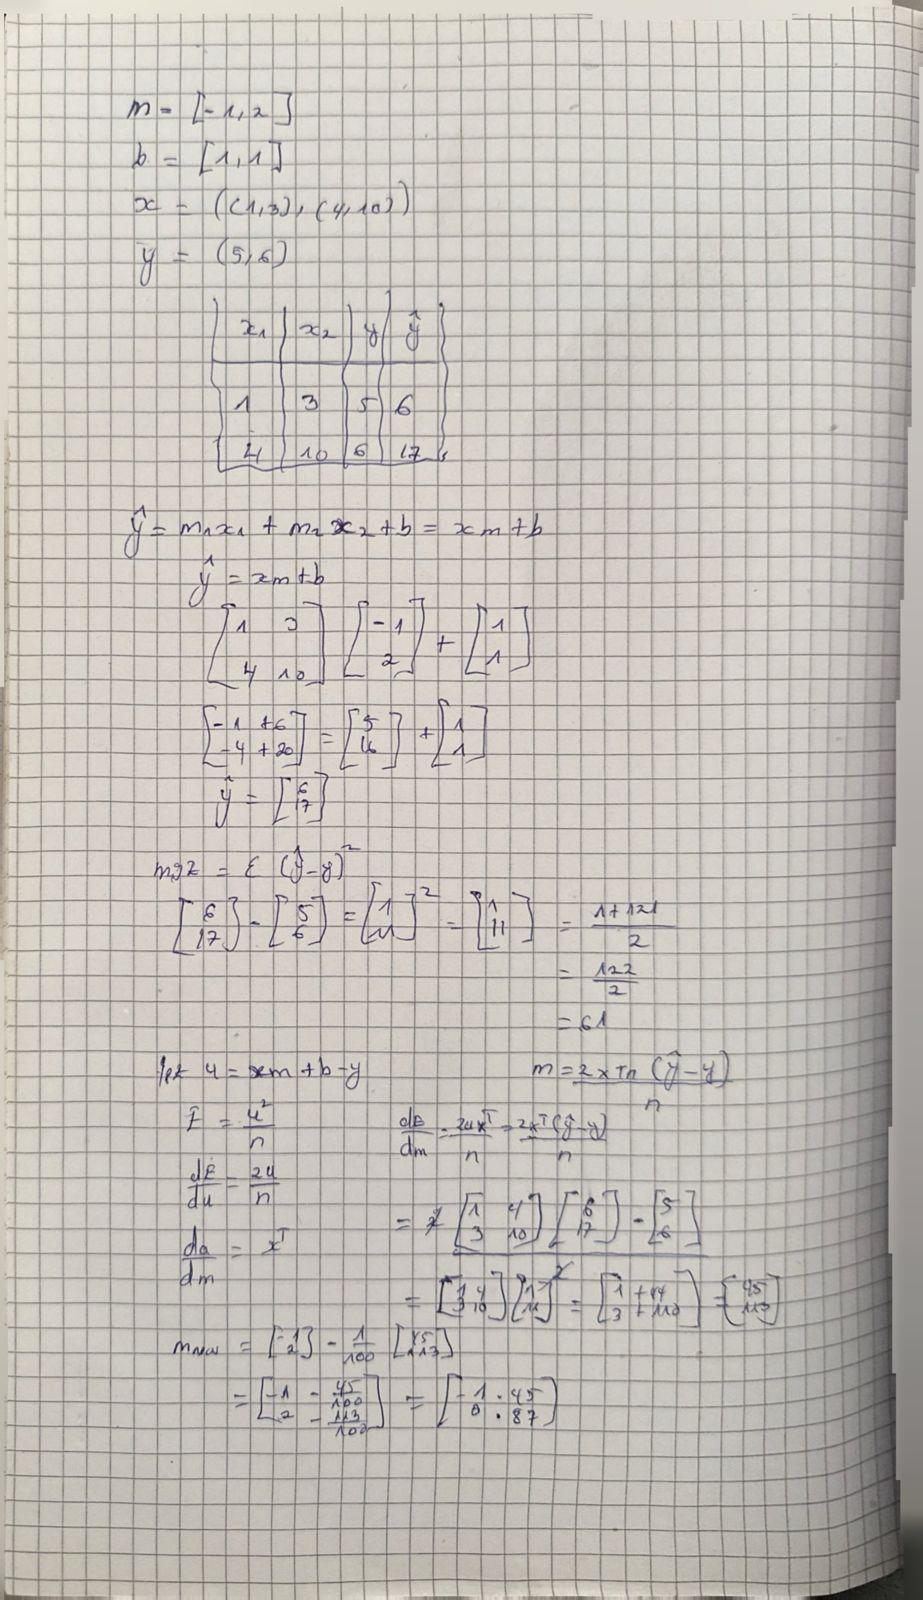

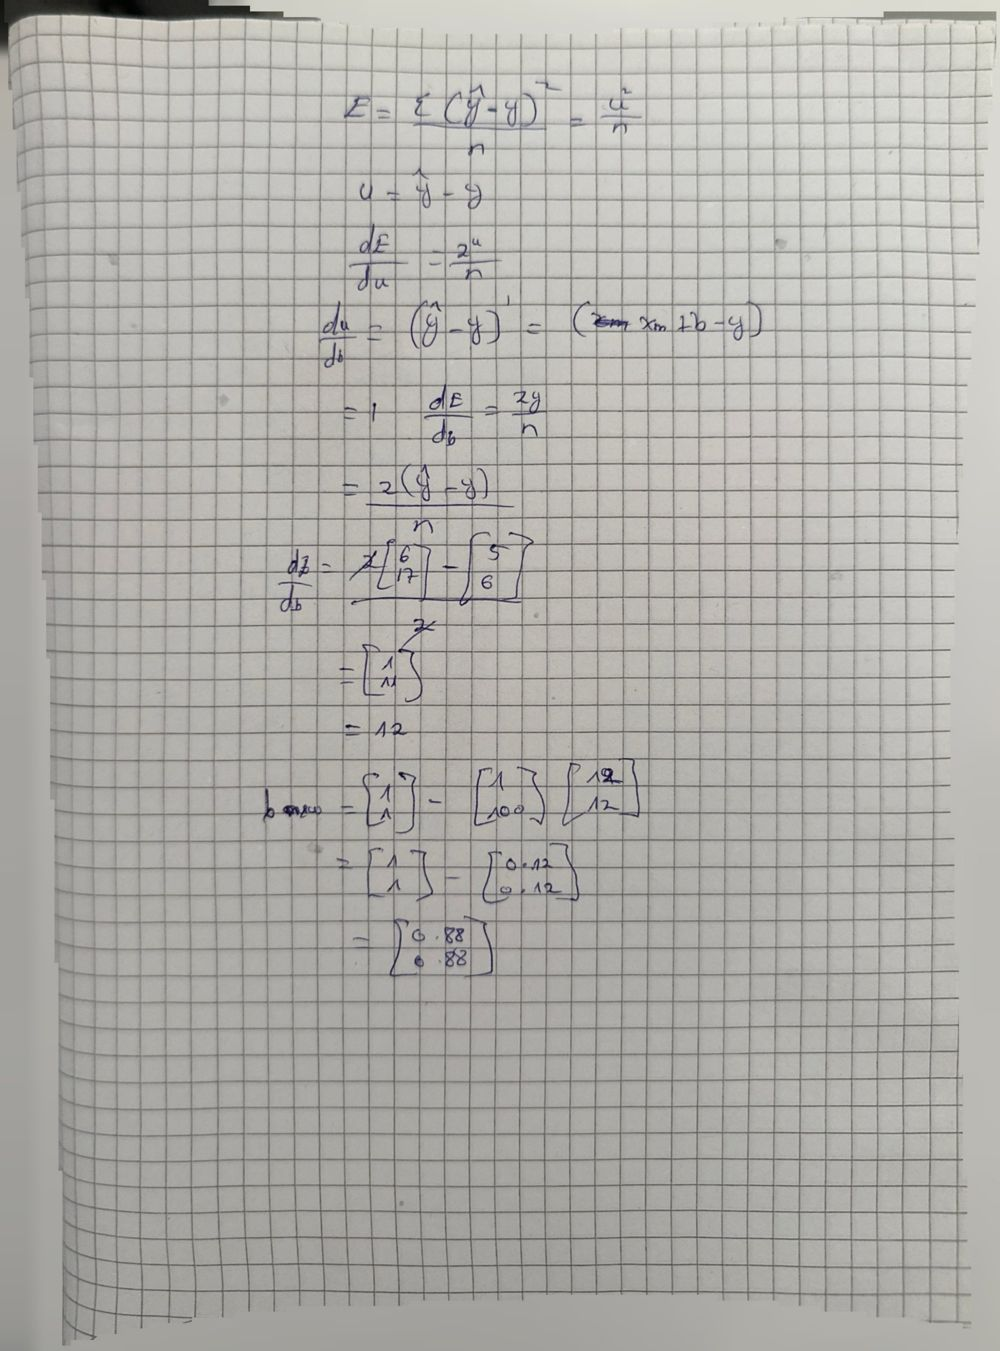

In [9]:
for page in ("part3_handwritten_page1.jpg", "part3_handwritten_page2.jpg"):
    display(Image(os.path.join(OUT, page), width=650))

---
## Part 4: Gradient descent in code

`derivative_of(equation, point)` takes **any** equation (a Python function of a parameter vector) and returns its partial derivatives using `scipy.differentiate.derivative`. At every update the code prints each step (prediction → error → MSE → matrix gradient → SciPy gradient → update), so nothing is hidden. The number of updates equals the number of group members (4).

In [10]:
print("SciPy derivative of the MSE equation at the starting point [m1, m2, b] = [-1, 2, 1]:")
print(gradient_descent.derivative_of(gradient_descent.mse_equation, [-1.0, 2.0, 1.0]), "\n")

m_final, b_final, hist = gradient_descent.main(members=gradient_descent.MEMBERS)

SciPy derivative of the MSE equation at the starting point [m1, m2, b] = [-1, 2, 1]:
[ 45. 113.  12.] 

X =
[[ 1.  3.]
 [ 4. 10.]]
y = [5. 6.]
m0 = [-1.  2.]  b0 = [1. 1.]  alpha = 0.01



--- Update 1 ---
m = [-1.000000, 2.000000]   b = [1.000000, 1.000000]
y_hat = X@m + b       = [6.000000, 17.000000]
e = y_hat - y         = [1.000000, 11.000000]
J (MSE)               = 61.000000
dJ/dm = (2/n) X^T e   = [45.000000, 113.000000]
dJ/db = (2/n) 1^T e   = 12.000000
SciPy [dm1, dm2, db]  = [45.000000, 113.000000, 12.000000]   (max diff 3.27e-13)
m_new = m - 0.01*dJ/dm = [-1.450000, 0.870000]
b_new = b - 0.01*dJ/db = [0.880000, 0.880000]
MSE after update      = 6.845000

--- Update 2 ---
m = [-1.450000, 0.870000]   b = [0.880000, 0.880000]
y_hat = X@m + b       = [2.040000, 3.780000]
e = y_hat - y         = [-2.960000, -2.220000]
J (MSE)               = 6.845000
dJ/dm = (2/n) X^T e   = [-11.840000, -31.080000]
dJ/db = (2/n) 1^T e   = -5.180000
SciPy [dm1, dm2, db]  = [-11.840000, -31.080000, -5.180000]   (max diff 4.26e-14)
m_new = m - 0.01*dJ/dm = [-1.331600, 1.180800]
b_new = b - 0.01*dJ/db = [0.931800, 0.931800]
MSE after update      = 2.723817

--- Update 3 ---
m = [-1.33


Saved outputs/part4_params_over_iterations.png, outputs/part4_error_over_iterations.png, outputs/part4_gd_log.txt


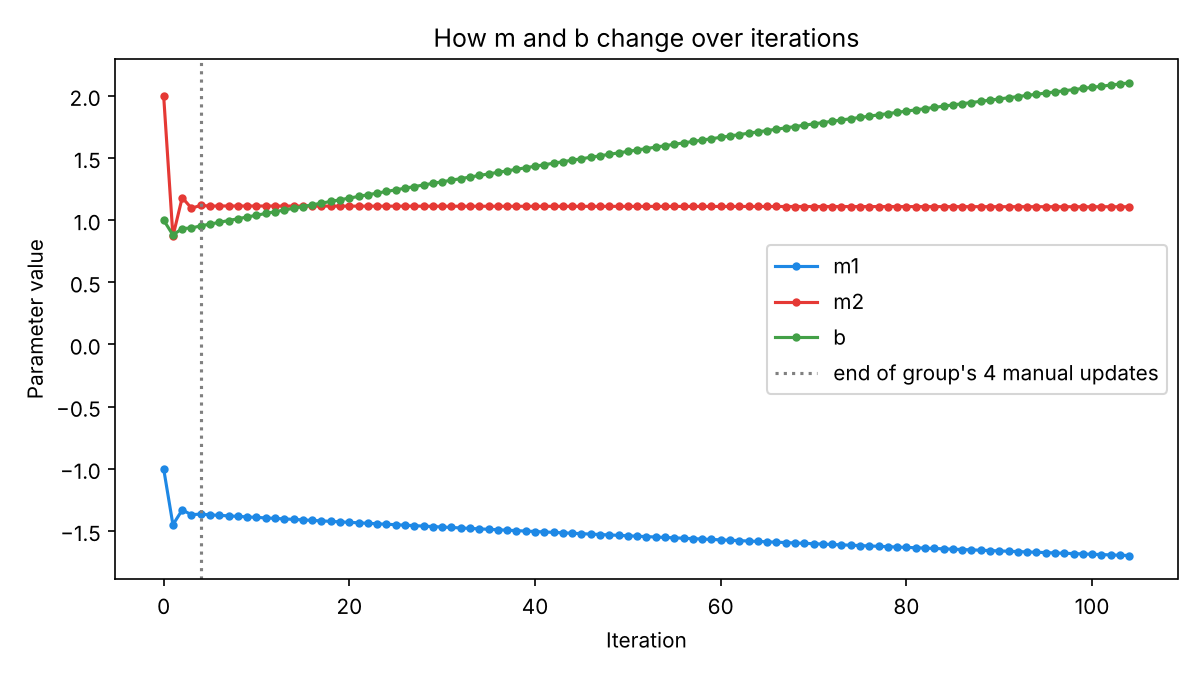

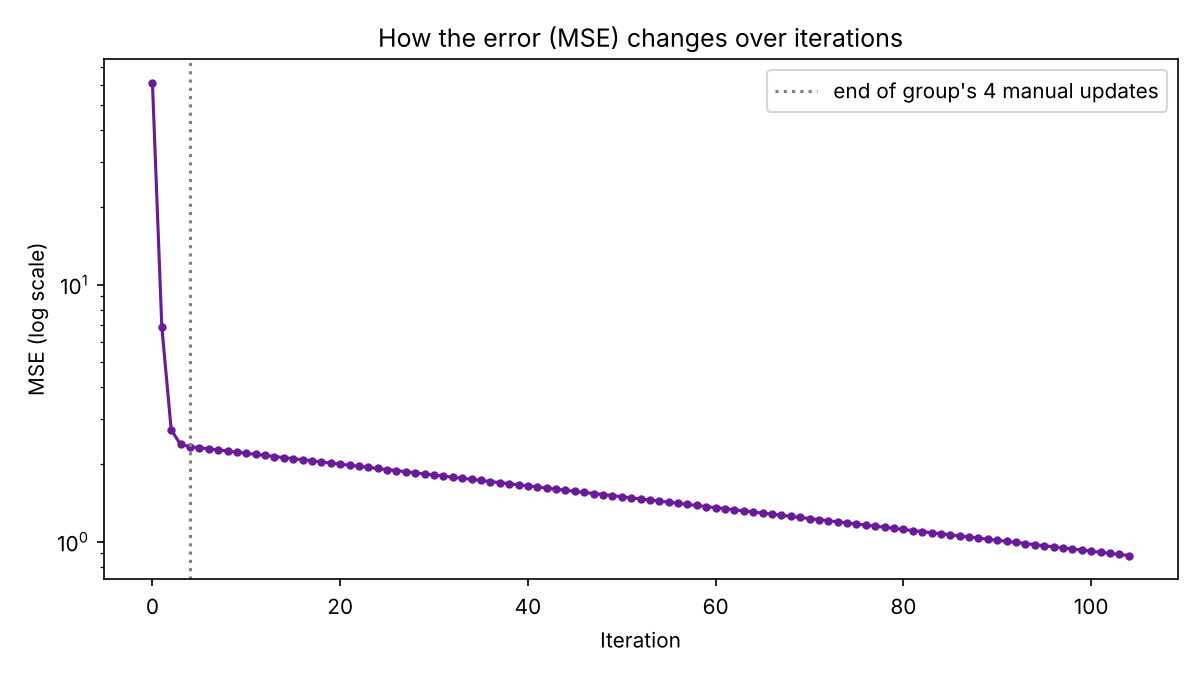

In [11]:
display(Image(os.path.join(OUT, "part4_params_over_iterations.png"), width=650))
display(Image(os.path.join(OUT, "part4_error_over_iterations.png"), width=650))

**Trend.** The error falls after every update (61 → 6.85 → 2.72 → 2.39 → 2.34), so m and b are moving in a direction that reduces the error.
- **The first step is large and overshoots.** Both predictions start too high (e = [1, 11]). m₂ multiplies the larger x₂ values (3 and 10), so it gets the biggest gradient and drops from 2 to 0.87, which pushes both predictions too low.
- **Then m₂ zig-zags** (1.18, 1.10, 1.12) while b climbs slowly (0.88 → 0.95). Zig-zagging like this is typical of a long, narrow valley in the cost surface.
- **In the long run** (plots above, 100+ updates), the MSE keeps falling. m₂ settles near 1.11, but m₁ keeps drifting down and b keeps drifting up. With 3 parameters and only 2 data points there are many exact fits, so gradient descent slides slowly along a flat valley towards one of them.